# 03 — Data Cleaning dan Preprocessing: Rain in Australia

**Proyek akhir Data Science 2026/2027**  
**Metode yang direncanakan:** Gaussian Naive Bayes dan Random Forest  
**Tahap CRISP-DM:** Data Preparation (lanjutan dari `02_Data_Understanding.ipynb`)

## Tujuan notebook

1. Mendokumentasikan **audit kualitas data**: missing value, duplikasi, nilai tidak valid, dan outlier.
2. Menetapkan aturan **cleaning** dan membandingkan kondisi sebelum–sesudah.
3. Melakukan **train/test split kronologis** sesuai rancangan Data Understanding (cutoff 8 Agustus 2015 jika CSV versi yang sama).
4. Menjalankan **imputasi, encoding, dan scaling** dengan *fit* pada training saja, sehingga tidak ada **data leakage** dari test.
5. Menghitung **ketidakseimbangan kelas** dan bobot kelas untuk rencana Random Forest.

**Batasan:** notebook ini **tidak melatih model** dan **tidak melakukan feature selection final**. Dua hal tersebut dikerjakan pada tahap berikutnya. Nilai numerik hasil akhir harus berasal dari output saat notebook benar-benar dijalankan; jangan menuliskan angka yang belum diuji.

**Integritas data:** `weatherAUS.csv` dibaca tanpa pernah ditimpa. Simpan file ini sejajar dengan CSV atau letakkan CSV dalam subfolder `data/`.

## 1. Persiapan environment

Pilih kernel VS Code yang sudah memiliki `pandas`, `numpy`, `scikit-learn`, dan `matplotlib`. Jika muncul `ModuleNotFoundError`, instal paket pada **kernel yang aktif** melalui sel baru dengan `%pip install pandas numpy scikit-learn matplotlib`, lalu *Restart Kernel*.

Versi scikit-learn yang digunakan perlu mendukung parameter `sparse_output` pada `OneHotEncoder` (versi 1.2 atau lebih baru).

In [10]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.15
Pandas: 3.0.5
Scikit-learn: 1.9.0


## 2. Memuat dataset asli

Pencarian file dibuat konsisten dengan notebook Data Understanding. Setelah dijalankan, periksa lokasi file serta ukuran dataset yang tercetak.

In [11]:
candidate_paths = [Path("weatherAUS.csv"), Path("data/weatherAUS.csv")]
dataset_path = next((p for p in candidate_paths if p.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "weatherAUS.csv tidak ditemukan. Letakkan di folder notebook atau data/weatherAUS.csv."
    )

df_raw = pd.read_csv(dataset_path, low_memory=False)
required_columns = {"Date", "Location", "RainTomorrow"}
missing_columns = required_columns - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ada: {sorted(missing_columns)}")

print("File dataset:", dataset_path.resolve())
print("Ukuran dataset asli:", df_raw.shape)
display(df_raw.head())

File dataset: D:\Lahar V2\Project\Project Akhir Data Science\weatherAUS.csv
Ukuran dataset asli: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


## 3. Audit kualitas data — SEBELUM cleaning

Hasil audit diambil dari **data mentah**. Ringkasan IQR dipakai untuk **mendeteksi** nilai ekstrem, bukan langsung membuang pengamatan. Pada data cuaca, curah hujan tinggi mungkin benar-benar terjadi.

Kriteria validasi sederhana:
- `Rainfall`, `Evaporation`, `Sunshine`, dan kecepatan angin tidak boleh negatif.
- Kelembapan relatif berada dalam rentang 0–100%.
- Kode `Cloud9am/Cloud3pm` bernilai 9 **tidak otomatis** dianggap salah, karena bisa memiliki arti khusus pada data meteorologi.

In [12]:
missing_before = df_raw.isna().sum().sort_values(ascending=False)
summary_before = {
    "baris": len(df_raw),
    "kolom": df_raw.shape[1],
    "missing_semua_sel": int(df_raw.isna().sum().sum()),
    "baris_dengan_missing": int(df_raw.isna().any(axis=1).sum()),
    "missing_target": int(df_raw["RainTomorrow"].isna().sum()),
    "duplikat_baris": int(df_raw.duplicated().sum()),
    "duplikat_tanggal_lokasi": int(df_raw.duplicated(subset=["Date", "Location"]).sum()),
}
print("KONDISI AWAL")
display(pd.Series(summary_before, name="Nilai").to_frame())

audit_missing = pd.DataFrame({
    "Jumlah missing": missing_before,
    "Persentase (%)": (df_raw.isna().mean() * 100).reindex(missing_before.index).round(2),
})
display(audit_missing)

numeric_raw = df_raw.select_dtypes(include="number")
outlier_records = []
for col in numeric_raw.columns:
    s = numeric_raw[col].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    n_outlier = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    outlier_records.append({"Fitur": col, "IQR outlier": n_outlier,
                            "Persen baris (%)": round(100 * n_outlier / len(df_raw), 2)})
print("Deteksi outlier IQR (bukan penghapusan otomatis):")
display(pd.DataFrame(outlier_records).sort_values("IQR outlier", ascending=False))

KONDISI AWAL


,Nilai
baris,145460
kolom,23
missing_semua_sel,343248
baris_dengan_missing,89040
missing_target,3267
duplikat_baris,0
duplikat_tanggal_lokasi,0


,Jumlah missing,Persentase (%)
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10


Deteksi outlier IQR (bukan penghapusan otomatis):


,Fitur,IQR outlier,Persen baris (%)
2,Rainfall,25578,17.58
5,WindGustSpeed,3092,2.13
7,WindSpeed3pm,2523,1.73
3,Evaporation,1995,1.37
6,WindSpeed9am,1817,1.25
8,Humidity9am,1425,0.98
10,Pressure9am,1191,0.82
11,Pressure3pm,919,0.63
15,Temp3pm,764,0.53
1,MaxTemp,489,0.34


## 4. Cleaning deterministik tanpa memanfaatkan informasi test

Aturan yang diterapkan:

1. Menghapus baris duplikat identik.
2. Memastikan kolom `Date` dapat dibaca sebagai tanggal; baris tanpa tanggal valid tidak dapat masuk pembagian kronologis.
3. Menghapus baris yang tidak memiliki label `RainTomorrow` valid (`Yes` atau `No`). **Label target tidak diimputasi.**
4. Nilai numerik yang jelas tidak valid (misalnya kelembapan >100%, curah hujan negatif) diubah menjadi `NaN` untuk ditangani melalui imputasi **berdasarkan training**.
5. Menghapus `RISK_MM` **jika ada**, karena mewakili informasi hujan yang berkaitan langsung dengan hari berikutnya dan berisiko membocorkan target.

**Catatan:** missing value pada fitur **belum diimputasi** di tahap ini. Imputasi dipasang dalam pipeline setelah train/test split.

In [13]:
df_clean = df_raw.copy()
df_clean = df_clean.drop_duplicates().copy()
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")
df_clean = df_clean.dropna(subset=["Date"]).copy()
df_clean = df_clean[df_clean["RainTomorrow"].isin(["Yes", "No"])].copy()

invalid_value_counts = {}
nonnegative_cols = ["Rainfall", "Evaporation", "Sunshine", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]
for col in nonnegative_cols:
    if col in df_clean.columns:
        bad = df_clean[col].notna() & (df_clean[col] < 0)
        invalid_value_counts[col] = int(bad.sum())
        df_clean.loc[bad, col] = np.nan

for col in ["Humidity9am", "Humidity3pm"]:
    if col in df_clean.columns:
        bad = df_clean[col].notna() & ~df_clean[col].between(0, 100)
        invalid_value_counts[col] = int(bad.sum())
        df_clean.loc[bad, col] = np.nan

# Kebocoran target pada beberapa varian dataset cuaca
leakage_cols = [c for c in ["RISK_MM"] if c in df_clean.columns]
df_clean = df_clean.drop(columns=leakage_cols)

comparison_cleaning = pd.DataFrame({
    "Indikator": ["Jumlah baris", "Missing target", "Duplikat baris", "Missing seluruh sel", "Missing pada fitur"],
    "Sebelum": [len(df_raw), int(df_raw["RainTomorrow"].isna().sum()),
               int(df_raw.duplicated().sum()), int(df_raw.isna().sum().sum()),
               int(df_raw.drop(columns=["RainTomorrow"]).isna().sum().sum())],
    "Sesudah cleaning awal": [len(df_clean), int(df_clean["RainTomorrow"].isna().sum()),
               int(df_clean.duplicated().sum()), int(df_clean.isna().sum().sum()),
               int(df_clean.drop(columns=["RainTomorrow"]).isna().sum().sum())],
})
display(comparison_cleaning)
print("Nilai tidak valid yang diubah menjadi NaN:", invalid_value_counts)
print("Fitur potensi leakage yang dibuang:", leakage_cols)
print("Catatan: fitur masih bisa mengandung missing, karena imputasi belum dilakukan.")

,Indikator,Sebelum,Sesudah cleaning awal
0,Jumlah baris,145460,142193
1,Missing target,3267,0
2,Duplikat baris,0,0
3,Missing seluruh sel,343248,316559
4,Missing pada fitur,339981,316559


Nilai tidak valid yang diubah menjadi NaN: {'Rainfall': 0, 'Evaporation': 0, 'Sunshine': 0, 'WindGustSpeed': 0, 'WindSpeed9am': 0, 'WindSpeed3pm': 0, 'Humidity9am': 0, 'Humidity3pm': 0}
Fitur potensi leakage yang dibuang: []
Catatan: fitur masih bisa mengandung missing, karena imputasi belum dilakukan.


## 5. Train/test split kronologis (80% tanggal awal / 20% tanggal akhir)

Cutoff dihitung dari **80% tanggal unik pada dataset asli**, sesuai rancangan `02_Data_Understanding.ipynb`. Untuk CSV yang sama, cutoff yang diharapkan adalah **2015-08-08**.

Karena target `RainTomorrow` berarti hujan **hari berikutnya**, kita menerapkan **purge gap 1 hari kalender** pada akhir training. Pengamatan sehari sebelum cutoff tidak digunakan untuk training agar label training tidak memanfaatkan kejadian di tanggal awal testing. Ini membuat jumlah baris training sedikit lebih kecil daripada subset eksplorasi EDA sebelumnya.

**Larangan:** jangan menggunakan label atau distribusi data test untuk memutuskan metode imputasi, pemilihan fitur, atau hyperparameter.

In [14]:
raw_dates = pd.to_datetime(df_raw["Date"], errors="coerce").dropna()
unique_dates = pd.Series(raw_dates.unique()).sort_values().reset_index(drop=True)
if len(unique_dates) < 10:
    raise ValueError("Tanggal unik terlalu sedikit untuk split kronologis")

cutoff = pd.Timestamp(unique_dates.iloc[int(len(unique_dates) * 0.80)])
purge_gap_days = 1
train_end_exclusive = cutoff - pd.Timedelta(days=purge_gap_days)

train_df = df_clean[df_clean["Date"] < train_end_exclusive].copy()
test_df = df_clean[df_clean["Date"] >= cutoff].copy()
purged_df = df_clean[(df_clean["Date"] >= train_end_exclusive) &
                     (df_clean["Date"] < cutoff)].copy()
if train_df.empty or test_df.empty:
    raise ValueError("Hasil split kosong. Periksa tanggal dan file CSV.")
assert train_df["Date"].max() < test_df["Date"].min()

print("Batas test:", cutoff.date())
print("Train sampai:", train_df["Date"].max().date())
print("Test mulai:", test_df["Date"].min().date())
print("Baris training:", len(train_df))
print("Baris test:", len(test_df))
print("Baris purge gap:", len(purged_df))
print("Baris label invalid yang sudah dibuang:", len(df_raw) - len(df_clean))

print("Distribusi target TRAIN:")
display(train_df["RainTomorrow"].value_counts(dropna=False).to_frame("Jumlah"))
print("Distribusi target TEST (hanya audit; jangan dipakai untuk tuning):")
display(test_df["RainTomorrow"].value_counts(dropna=False).to_frame("Jumlah"))

Batas test: 2015-08-08
Train sampai: 2015-08-06
Test mulai: 2015-08-08
Baris training: 109254
Baris test: 32891
Baris purge gap: 48
Baris label invalid yang sudah dibuang: 3267
Distribusi target TRAIN:


,Jumlah
RainTomorrow,
No,84594
Yes,24660


Distribusi target TEST (hanya audit; jangan dipakai untuk tuning):


,Jumlah
RainTomorrow,
No,25680
Yes,7211


## 6. Menyiapkan fitur dan target

- `RainTomorrow` adalah **target** dan tidak boleh masuk `X`.
- `Date` dipakai untuk split dan **dikeluarkan dari fitur awal**. Feature engineering terkait musim/tanggal dapat diputuskan pada tahap berikutnya.
- `Location` tetap menjadi fitur kategorikal.
- Semua kolom selain target, tanggal, dan fitur bocor menjadi **kandidat fitur**. Pemilihan fitur final dilakukan di notebook 04.

Nilai kosong pada fitur akan diproses dengan **median untuk fitur numerik** dan **modus untuk fitur kategorikal**. Fitur kategorikal menggunakan **One-Hot Encoding**. Fitur numerik menggunakan **StandardScaler** agar representasinya juga sesuai untuk Gaussian Naive Bayes; Random Forest sendiri umumnya tidak memerlukan scaling.

In [15]:
excluded_features = ["RainTomorrow", "Date"]
feature_columns = [c for c in train_df.columns if c not in excluded_features]
X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()
y_train = train_df["RainTomorrow"].map({"No": 0, "Yes": 1}).astype(int)
y_test = test_df["RainTomorrow"].map({"No": 0, "Yes": 1}).astype(int)

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print("Jumlah fitur kandidat:", len(feature_columns))
print("Fitur numerik (", len(numeric_features), "):", numeric_features)
print("Fitur kategorikal (", len(categorical_features), "):", categorical_features)
print("Dimensi X_train sebelum preprocessing:", X_train.shape)
print("Dimensi X_test sebelum preprocessing:", X_test.shape)

Jumlah fitur kandidat: 21
Fitur numerik ( 16 ): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Fitur kategorikal ( 5 ): ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']
Dimensi X_train sebelum preprocessing: (109254, 21)
Dimensi X_test sebelum preprocessing: (32891, 21)


## 7. Pipeline preprocessing: fit pada TRAIN saja

**Pencegahan data leakage:** `.fit_transform()` dilakukan hanya pada `X_train`. Data `X_test` diproses memakai `.transform()` tanpa melakukan fit lagi. 

Pengubahan menjadi matriks *dense* dipilih agar nantinya kompatibel dengan `GaussianNB`. Jika memori perangkat terbatas, pendekatan sparse untuk Random Forest dan preprocessing khusus GaussianNB dapat dipisahkan pada tahap Modeling.

In [16]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
], remainder="drop", sparse_threshold=0)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
feature_names_after = preprocessor.get_feature_names_out()

print("X_train setelah preprocessing:", X_train_processed.shape)
print("X_test setelah preprocessing:", X_test_processed.shape)
print("Jumlah fitur hasil encoding:", len(feature_names_after))
print("Jumlah missing hasil train:", int(pd.isna(X_train_processed).sum()))
print("Jumlah missing hasil test:", int(pd.isna(X_test_processed).sum()))
assert np.isfinite(X_train_processed).all(), "Ada nilai NaN/inf dalam training setelah transformasi"
assert np.isfinite(X_test_processed).all(), "Ada nilai NaN/inf dalam testing setelah transformasi"

print("Contoh 15 fitur hasil encoding:")
display(pd.DataFrame({"Fitur": feature_names_after[:15]}))

X_train setelah preprocessing: (109254, 115)
X_test setelah preprocessing: (32891, 115)
Jumlah fitur hasil encoding: 115
Jumlah missing hasil train: 0
Jumlah missing hasil test: 0
Contoh 15 fitur hasil encoding:


,Fitur
0,num__MinTemp
1,num__MaxTemp
2,num__Rainfall
3,num__Evaporation
4,num__Sunshine
5,num__WindGustSpeed
6,num__WindSpeed9am
7,num__WindSpeed3pm
8,num__Humidity9am
9,num__Humidity3pm


## 8. Perbandingan sebelum–sesudah imputasi dan encoding

Tabel ini melengkapi item penilaian **kondisi sebelum vs sesudah dibersihkan**. Baris tidak berubah ketika melakukan transformasi fitur; jumlah kolom justru bertambah karena one-hot encoding. Seluruh nilai hilang pada matriks fitur ditangani menggunakan parameter yang hanya dipelajari dari training.

**Interpretasi:** jumlah missing pada data mentah dan data hasil pembersihan awal mungkin berbeda karena ada baris dengan label target kosong yang dihapus. Missing pada dataset fitur setelah imputasi diharapkan 0, tanpa memakai statistik testing.

,Indikator,Sebelum preprocessing,Sesudah preprocessing
0,Baris training,109254,109254
1,Jumlah kolom fitur training,21,115
2,Missing fitur training,224337,0
3,Missing fitur testing,92094,0
4,Jumlah kolom setelah encoding,21,115
5,Baris test,32891,32891


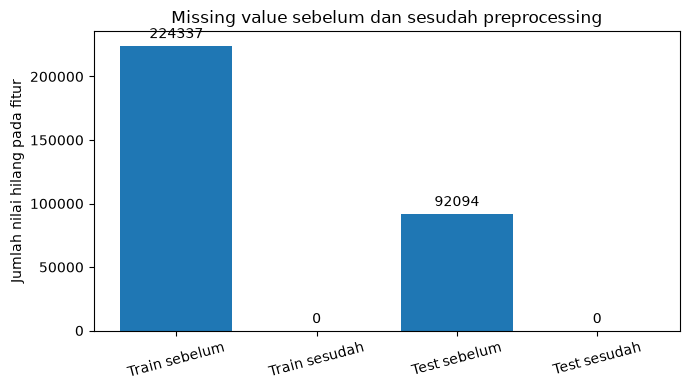

In [17]:
preprocessing_comparison = pd.DataFrame({
    "Indikator": ["Baris training", "Jumlah kolom fitur training",
                  "Missing fitur training", "Missing fitur testing",
                  "Jumlah kolom setelah encoding", "Baris test"],
    "Sebelum preprocessing": [len(X_train), X_train.shape[1],
                               int(X_train.isna().sum().sum()),
                               int(X_test.isna().sum().sum()),
                               X_train.shape[1], len(X_test)],
    "Sesudah preprocessing": [len(X_train_processed), X_train_processed.shape[1],
                               int(pd.isna(X_train_processed).sum()),
                               int(pd.isna(X_test_processed).sum()),
                               X_train_processed.shape[1], len(X_test_processed)],
})
display(preprocessing_comparison)

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["Train sebelum", "Train sesudah", "Test sebelum", "Test sesudah"]
counts = [int(X_train.isna().sum().sum()), int(pd.isna(X_train_processed).sum()),
          int(X_test.isna().sum().sum()), int(pd.isna(X_test_processed).sum())]
bars = ax.bar(labels, counts)
ax.bar_label(bars, padding=3)
ax.set_ylabel("Jumlah nilai hilang pada fitur")
ax.set_title("Missing value sebelum dan sesudah preprocessing")
ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.show()

## 9. Ketidakseimbangan kelas dan strategi penanganan

Evaluasi pada Data Understanding menemukan kelas `RainTomorrow=No` lebih dominan. Untuk tahap Modeling:

- Gunakan metrik **precision, recall, F1-score**, dan **confusion matrix**, bukan accuracy saja.
- Hitung `class_weight='balanced'` **berdasarkan target training saja** untuk kandidat `RandomForestClassifier`.
- Untuk `GaussianNB`, pertimbangkan evaluasi dengan bobot sampel training apabila diperlukan; jangan menyatakan metode tersebut telah diuji sebelum model dijalankan.
- **Jangan melakukan oversampling pada test**. Jika mencoba SMOTE atau resampling, terapkan hanya pada training dan validasi dalam pipeline yang benar.

Di notebook ini **kita menghitung bobot kelas, belum melatih model.**

In [18]:
class_counts = y_train.value_counts().sort_index()
class_percent = (class_counts / len(y_train) * 100).round(2)
classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(cls): float(weight) for cls, weight in zip(classes, weights)}

class_summary = pd.DataFrame({
    "Label": ["No", "Yes"],
    "Kode": [0, 1],
    "Jumlah training": [int(class_counts.get(0, 0)), int(class_counts.get(1, 0))],
    "Persentase (%)": [float(class_percent.get(0, 0)), float(class_percent.get(1, 0))],
    "Class weight (rencana RF)": [class_weights[0], class_weights[1]],
})
display(class_summary)
print("Bobot kelas yang bisa dipakai pada RandomForestClassifier(class_weight=...):")
print(class_weights)

,Label,Kode,Jumlah training,Persentase (%),Class weight (rencana RF)
0,No,0,84594,77.43,0.645755
1,Yes,1,24660,22.57,2.215207


Bobot kelas yang bisa dipakai pada RandomForestClassifier(class_weight=...):
{0: 0.6457550180863891, 1: 2.215206812652068}


## 10. Rangkuman keputusan untuk presentasi Progress 2

| Item dosen | Bukti dalam notebook | Keputusan |
|---|---|---|
| Audit missing, outlier, duplikasi | Bagian 2 | Audit sebelum pembersihan, outlier IQR tidak otomatis dibuang. |
| Cleaning | Bagian 3 | Buang label kosong/invalid, duplikasi, tanggal invalid; numerik mustahil menjadi `NaN`. |
| Sebelum vs sesudah | Bagian 3 dan 7 | Tabel perbandingan dan grafik missing value. |
| Encoding, scaling, imbalance | Bagian 5–8 | Median, modus, OHE, StandardScaler, audit rasio kelas, bobot kelas untuk RF. |
| Train/test split | Bagian 4 | 80% tanggal awal vs 20% akhir, dengan gap 1 hari karena target hujan esok hari. |
| Feature selection | **Notebook 04 (belum dilakukan)** | Keputusan berbasis EDA dan bukti pada training saja. |

### Ketentuan langkah selanjutnya

1. Buka `04_Feature_Selection.ipynb` **setelah** hasil kode notebook ini sukses dieksekusi.
2. Lakukan pemilihan fitur tanpa melihat kinerja pada test, misalnya berdasarkan rasio missing, korelasi redundan, dan alasan meteorologis dari subset training.
3. Buat model di notebook `05_Modeling.ipynb`, latih hanya pada training, dan evaluasi test di `06_Evaluation.ipynb`.
4. Untuk pengujian yang benar-benar independen, lakukan semua pemilihan hyperparameter melalui validasi pada training saja. Jangan memperlakukan hasil test sebagai dasar mengubah fitur atau preprocessing.

**Catatan metodologis:** persentase data latih dan uji dapat sedikit berbeda dari 80:20 berdasarkan baris, karena pembagian didasarkan pada **tanggal unik**, target kosong dihapus, dan ada gap satu hari.